<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT_422_%7C_HW_4_1_%2B_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MAT 422 | 4.1 + 2 : Graphs and Graph Modeling

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=3, suppress=True)


#Graph Basic and Adjacency Representations
The adjacency matrix provides a numerical way to organize graphical information. The rows and column represtation is a representation of an object, and the values inside indicate a relationship using 0 and 1 for its non or its existence between the column and row.

In [7]:

nodes = ["A", "B", "C", "D", "E", "F"]

edges = [
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "F"),
    ("E", "F")
]

index = {node: i for i, node in enumerate(nodes)}

adj = np.zeros((len(nodes), len(nodes)), dtype=int)

for u, v in edges:
    adj[index[u], index[v]] = 1
    adj[index[v], index[u]] = 1

print("Adjacency Matrix:")
print(adj)

print("Is the matrix symmetric?", np.array_equal(adj, adj.T))


Adjacency Matrix:
[[0 1 1 0 0 0]
 [1 0 0 1 0 0]
 [1 0 0 1 1 0]
 [0 1 1 0 0 1]
 [0 0 1 0 0 1]
 [0 0 0 1 1 0]]
Is the matrix symmetric? True


#Degree and Neighbors
Using a degree is a means for which one can determine direct connection that a specific node has. Each points degree represents the number of associated nodes that are affialited with it in its network. With this information, one can compare how different pieces of information are connected within a network.

In [11]:
adj_list = {node: [] for node in nodes}

for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

print("Adjacency List:")
print(adj_list)

print("\nDegrees:")
for node in nodes:
    print(node, ":", len(adj_list[node]))

print("\nNeighbors of C:")
print(adj_list["C"])

Adjacency List:
{'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'D', 'E'], 'D': ['B', 'C', 'F'], 'E': ['C', 'F'], 'F': ['D', 'E']}

Degrees:
A : 2
B : 2
C : 3
D : 3
E : 2
F : 2

Neighbors of C:
['A', 'D', 'E']


#Graph tranversal
This method is a means for which visiting nodes are explored from its neighbors towards other neighbors. Each node is only visted one as the algorithm is tracking which nodes have and haven't been visited.

BFS starting from A:
['A', 'B', 'C', 'D', 'E', 'F']
Number of nodes visited: 6


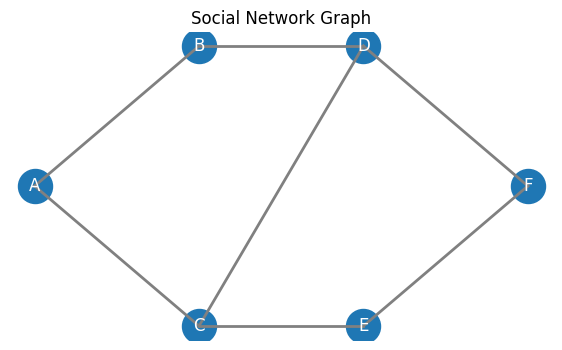

In [15]:

def bfs(start):
    seen = {start}
    order = []
    queue = deque([start])

    while queue:
        node = queue.popleft()
        order.append(node)

        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append(neighbor)

    return order

result = bfs("A")

print("BFS starting from A:")
print(result)

print("Number of nodes visited:", len(result))


positions = {
    "A": (0, 1),
    "B": (1, 2),
    "C": (1, 0),
    "D": (2, 2),
    "E": (2, 0),
    "F": (3, 1)
}

plt.figure(figsize=(7, 4))

for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2)

for node, (x, y) in positions.items():
    plt.scatter(x, y, s=600, color="tab:blue")
    plt.text(x, y, node, color="white",
             ha="center", va="center", fontsize=12)

plt.title("Social Network Graph")
plt.axis("off")
plt.show()


#Graph and Modeling
Graphs as a means to display information visually but here, one can notice that through the connections between the edges linking the nodes. This acts as a means for information spread and wave function modeling disease or communication travel.

In [13]:
informed = {"A"}

print("Initially informed:", sorted(informed))

for round_num in range(1, 4):
    new_informed = set()

    for node in informed:
        for neighbor in adj_list[node]:
            if neighbor not in informed:
                new_informed.add(neighbor)

    informed.update(new_informed)

    print("After round", round_num, ":", sorted(informed))


Initially informed: ['A']
After round 1 : ['A', 'B', 'C']
After round 2 : ['A', 'B', 'C', 'D', 'E']
After round 3 : ['A', 'B', 'C', 'D', 'E', 'F']


* I explained my sections in words before my code.
* I double checked my core numerical claims
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.